In [10]:
import pandas as pd

df = pd.read_csv("steamdb_ratings_limpio.csv")

# 1. ¿Cómo se distribuye el pico de jugadores?
print("peak describe")
print(df['peak'].describe())

# 2. ¿Cuál es el juego con más reseñas?
print("\nJuego con mas reseñas")
print(df.loc[df['reviews'].idxmax()])

# 3. Crear la variable objetivo
# Por ejemplo: Éxito si tiene más de 10,000 reseñas
print("\nPrueba de variable objetivo") 
df['exito'] = (df['reviews'] > 10000).astype(int)

# 4. ¿Cuántos juegos son "exitosos" bajo esta regla?
print("\nPrueba de regla")
df['exito'].value_counts()

peak describe
count    9.585000e+03
mean     7.613178e+03
std      5.381449e+04
min      1.000000e+00
25%      1.940000e+02
50%      6.110000e+02
75%      2.289000e+03
max      2.415714e+06
Name: peak, dtype: float64

Juego con mas reseñas
id                     5365.0
name         Counter-Strike 2
discount                  NaN
price                    Free
rating                 85.50%
release              Aug 2012
followers           4966114.0
reviews               9948791
peak                1862531.0
Name: 5364, dtype: object

Prueba de variable objetivo

Prueba de regla


exito
0    8271
1    1729
Name: count, dtype: int64

Accuracy: 0.9007170435741865

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94      1481
           1       0.67      0.90      0.77       332

    accuracy                           0.90      1813
   macro avg       0.82      0.90      0.85      1813
weighted avg       0.92      0.90      0.91      1813



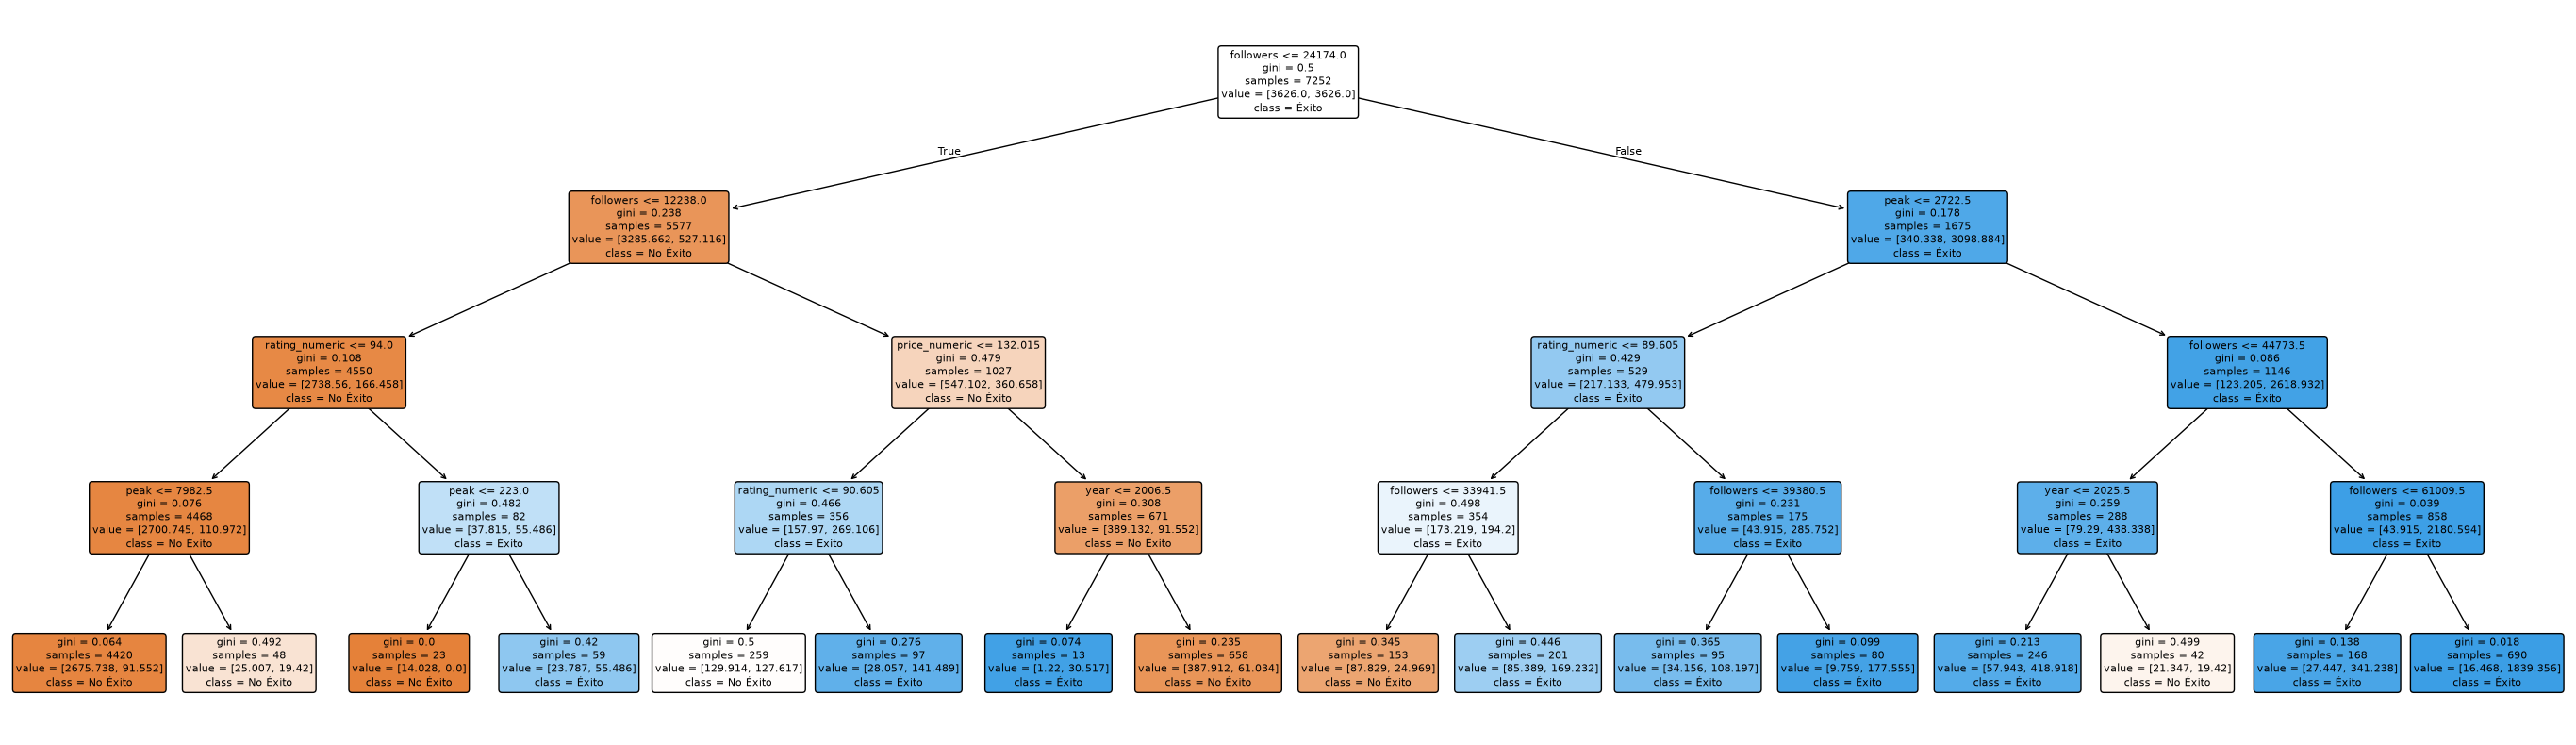

In [28]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report

# 1. Cargar datos
df = pd.read_csv("steamdb_ratings_limpio.csv")

# 2. Limpieza rápida
df = df.dropna(subset=['peak', 'followers'])

# --- LIMPIEZA DEL PRECIO ---
def limpiar_precio(x):
    if pd.isna(x): return np.nan
    if isinstance(x, str):
        x = x.strip()
        if x in ["—", "-", ""]: return np.nan
        if "Free" in x: return 0.0
        if "Mex$" in x:
            return float(x.replace("Mex$ ", "").replace(",", ""))
    return float(x)

df['price_numeric'] = df['price'].apply(limpiar_precio)

# --- LIMPIEZA DEL RATING ---
def limpiar_rating(x):
    if pd.isna(x): return np.nan
    if isinstance(x, str):
        x = x.strip()
        if x in ["—", "-", ""]: return np.nan
        if "%" in x:
            return float(x.replace("%", ""))
    return float(x)

df['rating_numeric'] = df['rating'].apply(limpiar_rating)

# --- EXTRAER EL AÑO ---
df['year'] = df['release'].str.extract(r'(\d{4})').astype(float)

# 3. Eliminar filas que se quedaron sin datos clave después de la limpieza
df = df.dropna(subset=['price_numeric', 'rating_numeric', 'year'])

# ============================================================
# ¡AQUÍ ESTÁ LA LÍNEA QUE FALTABA! 
# Creamos la variable objetivo: Éxito si tiene más de 10,000 reseñas
# ============================================================
df['exito'] = (df['reviews'] > 10000).astype(int)

# 4. Definir features y target
X = df[['price_numeric', 'year', 'followers', 'peak', 'rating_numeric']]
y = df['exito']

# 5. Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Entrenar árbol de decisión
# Usamos profundidad 4 para que el árbol no sea una telaraña gigante y sea interpretable
modelo = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
modelo.fit(X_train, y_train)

# 7. Predicciones y evaluación
y_pred = modelo.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

# 8. Graficar el árbol
plt.figure(figsize=(35, 10)) 

plot_tree(
    modelo, 
    feature_names=X.columns, 
    class_names=["No Éxito", "Éxito"], 
    filled=True, 
    rounded=True, 
    max_depth=4, 
    fontsize=8
)
plt.savefig("arbol_decision_visual.png", dpi=300, bbox_inches='tight')
plt.show()